# Task 2: gRNA design for FEV (CRISPRi)

**Why FEV?** It is **up** in SARS-CoV-2 (so we use **CRISPRi** to turn it down), protein-coding with one clear transcript, and on **chr2** (Task 3 has VCFs for chr1 and chr2).
CCDC163 had stronger statistics, but the supplied NCBI annotation calls it a *pseudogene*, so it is hard to defend as a target.

## How to reproduce this notebook
**Run it from the project root** (the folder that holds the two genome files below), then *Restart kernel and Run All*.

| Needed | Where |
|---|---|
| `GCF_000001405.26_GRCh38_genomic.fna.gz` (genome, ~946 MB) | project root |
| `GCF_000001405.26_GRCh38_genomic.gff.gz` (annotation) | project root |
| Python 3.10 + `pandas 2.3`, `biopython 1.88`, `requests 2.34`, `matplotlib 3.10` | `pip install -r task2/requirements.txt` |
| Internet (first run only) | CRISPOR web service |

**CRISPOR is a live web service.** The first run submits the exon to CRISPOR (job `CQB5uBy43ja6oQaniLKb`) and saves the results to
`task2/crispor_guides_allscores.tsv` and `task2/crispor_offtargets.tsv`. Later runs re-use those two files, so the numbers do not change.
Delete them to force a fresh CRISPOR run.

All outputs are written to `task2/`.


In [1]:
import gzip, os, re, time, bisect                  # standard tools: read .gz files, folders, text patterns, waiting
from collections import defaultdict                # dictionary that creates empty lists automatically

import pandas as pd                                # tables
import requests                                    # talk to the CRISPOR website
import matplotlib.pyplot as plt                    # plots
from Bio import SeqIO                              # read FASTA files
from Bio.Seq import Seq                            # DNA sequences (reverse complement, translate)

GENE  = "FEV"                                      # the gene we picked in Task 1
GFF   = "GCF_000001405.26_GRCh38_genomic.gff.gz"   # annotation: where genes and exons are
FASTA = "GCF_000001405.26_GRCh38_genomic.fna.gz"   # genome: the actual DNA letters
OUT   = "task2"                                    # folder for our results
FLANK = 25                                         # extra bases around the exon so edge PAMs are not missed
os.makedirs(OUT, exist_ok=True)                    # make the results folder if it is missing

## Find the first exon of FEV
Read the annotation (GFF) and collect FEV and its exons.
GFF positions are **1-based and inclusive**, but Python counts from 0, so we cut with `seq[start-1:end]`.

In [2]:
def parse_attributes(text):
    # turn "ID=x;Name=y" into {"ID": "x", "Name": "y"}
    return dict(item.split("=", 1) for item in text.strip().split(";") if "=" in item)

gene, transcripts = None, {}                       # will hold the gene and its transcripts
with gzip.open(GFF, "rt") as handle:               # open the compressed annotation as text
    for line in handle:                            # go through it line by line
        if line.startswith("#"):                   # skip header lines
            continue
        c = line.rstrip("\n").split("\t")          # the 9 tab-separated columns
        if len(c) < 9:                             # skip broken lines
            continue
        seqid, _, ftype, start, end, _, strand, _, attrs = c   # name the columns we need
        a = parse_attributes(attrs)                # read the attribute column
        if ftype == "gene" and a.get("Name") == GENE:           # this line is the FEV gene
            gene = dict(seqid=seqid, start=int(start), end=int(end), strand=strand,
                        biotype=a.get("gene_biotype"))
        elif gene and a.get("gene") == GENE:                    # lines that belong to FEV
            if ftype == "mRNA":                                 # a transcript of FEV
                transcripts[a["ID"]] = dict(name=a.get("Name"), exons=[])
            elif ftype == "exon" and a.get("Parent") in transcripts:   # an exon of that transcript
                transcripts[a["Parent"]]["exons"].append((int(start), int(end)))

print(gene)                                        # chromosome, start, end, strand, type
for t in transcripts.values():
    print(t["name"], "exons:", sorted(t["exons"]))

{'seqid': 'NC_000002.12', 'start': 218981087, 'end': 218985657, 'strand': '-', 'biotype': 'protein_coding'}
NM_017521.2 exons: [(218981087, 218982256), (218984231, 218984305), (218985024, 218985657)]


**The first exon is the first one in the direction of transcription.**
FEV is on the **minus** strand, so it is read from high to low positions: its first exon is the one with the **highest** coordinates, and we must reverse-complement the DNA.

In [3]:
strand = gene["strand"]                            # "-" for FEV
tx = next(iter(transcripts.values()))              # FEV has a single transcript
if strand == "+":
    exon = min(tx["exons"], key=lambda e: e[0])    # plus strand: lowest start is first
else:
    exon = max(tx["exons"], key=lambda e: e[1])    # minus strand: highest end is first
exon_start, exon_end = exon                        # coordinates of exon 1
tss = exon_start if strand == "+" else exon_end    # transcription start site (where the gene begins)
print(f"First exon: {gene['seqid']}:{exon_start}-{exon_end} ({strand}), "
      f"{exon_end - exon_start + 1} bp, TSS at {tss}")

First exon: NC_000002.12:218985024-218985657 (-), 634 bp, TSS at 218985657


Now cut the exon (plus a little flank) out of the genome file.

In [4]:
with gzip.open(FASTA, "rt") as handle:             # open the genome (large file, ~10 s)
    for rec in SeqIO.parse(handle, "fasta"):       # go chromosome by chromosome
        if rec.id == gene["seqid"]:                # stop at FEV's chromosome
            chrom = rec.seq
            break

def in_gene_direction(seq):
    # minus-strand gene: reverse-complement so the sequence reads like the gene does
    return seq if strand == "+" else seq.reverse_complement()

exon_seq   = in_gene_direction(chrom[exon_start - 1:exon_end]).upper()                    # exon 1 only
padded_seq = in_gene_direction(chrom[exon_start - 1 - FLANK:exon_end + FLANK]).upper()    # exon 1 + flank
gc = (exon_seq.count("G") + exon_seq.count("C")) / len(exon_seq)                          # fraction of G and C
print(f"Exon length {len(exon_seq)} bp, GC {gc:.1%}")

# sanity check
atg = str(exon_seq).find("ATGAGACAG")              # position of the start codon
print("Protein starts:", exon_seq[atg:atg + 18].translate())

str(exon_seq)                                      # show the exon sequence

Exon length 634 bp, GC 71.8%
Protein starts: MRQSGA


'GCGGCGAGTGGAGCGGGAGCCGACTGGAAGAAGGGCTCTAGGGAGGGGGCTGTGGCTGCTGGGGTCCGAGGTGGGGCCGGGTACACCAGCCCCATCACTGTTTGCAGAGAGTCAGGGAGGCGGAAAAGACACGCGCTCTAGGCTCCCATCAGGGCACATGGCCCGGGCCCATCCCCCGCGCGTCTCCCCGGCTGCGGGGCGCGGGGGGCTGCCGGGTGCGCTTGGCTGTGGCGCGGCGCGTTGGAGACTTTATTGCGATGGGACGATAAGAGGGGCGGGGGCGGGGTCCTGGGGGCCGAGGCGGCAGCGCTTTAATTAAAACGGAAATTGCGGCCCCGGGCCGCGCGGGGGCCGGAGGGTTCCAAGCGGCCCCTTAGCTGGAAGCGTTTCTCCAGGACCCCCCCGCAACCCCCGCCACGCCCGGGCTGCCCCCTCCCGCCAGGCCCTGCCGGACCCGGCGCCGTCTTCTCCTCCTTGTCACCCGCGGTCGCTTCGGGCGGGGATCGGTGCCACCGAGCGCAAAGCCTGCCTCGCCCCCCTTCCCCGTCCCCCCCATCTCCCACCGCCCAGTCCCCGGCGGCGATGAGACAGAGCGGCGCCTCCCAGCCCCTGCTGATCAACATGTACCTGCCAG'

## Discover candidate guides (Week 6 method)
A guide for *S. pyogenes* Cas9 is a **20 bp protospacer + `NGG` PAM** (23 bp in total). We find them with a **regular expression**, on **both strands** because DNA is double-stranded.

| Rule | Why |
|---|---|
| AT content between 20 % and 65 % | extreme AT/GC content lowers efficiency |
| No `TTTT` | it ends RNA polymerase III transcription (the guide would not be made) |
| Begins with a `G` | helps the U6 promoter start the guide |


In [5]:
exon = str(exon_seq)                                         # exon 1 in gene direction
exon_rc = str(exon_seq.reverse_complement())                 # the opposite strand
L = len(exon)                                                # exon length
pattern = re.compile(r"(?=([ACGT]{20}[ACGT]GG))")            # 20 nt + N + GG; the lookahead () also finds overlapping guides

cands = []
for strand_name, s in [("sense", exon), ("antisense", exon_rc)]:          # search both strands
    for m in pattern.finditer(s):                                          # every match
        full = m.group(1)                                                  # the 23-mer (guide + PAM)
        j = m.start()                                                      # where it starts on this strand
        first_base = j if strand_name == "sense" else L - 20 - j           # first guide base in gene direction
        cands.append(dict(seq23=full, protospacer=full[:20], pam=full[20:], strand=strand_name,
                          dist_from_TSS=first_base + 1))                   # bp after the TSS (1 = first base)
cands = pd.DataFrame(cands)

cands["AT"] = cands.protospacer.apply(lambda p: (p.count("A") + p.count("T")) / 20)   # AT fraction
cands["rule_AT"]    = cands.AT.between(0.20, 0.65)                         # rule 1: AT between 20 % and 65 %
cands["rule_noTTTT"] = ~cands.protospacer.str.contains("TTTT")             # rule 2: no poly-T
cands["rule_startG"] = cands.protospacer.str[0] == "G"                     # rule 3: starts with G
cands["workshop_ok"] = cands.rule_AT & cands.rule_noTTTT & cands.rule_startG

print(len(cands), "candidate guides in exon 1 (both strands)")
print("pass AT:", cands.rule_AT.sum(), "| no TTTT:", cands.rule_noTTTT.sum(),
      "| start with G:", cands.rule_startG.sum(), "| pass all three:", cands.workshop_ok.sum())
cands.head(3)

186 candidate guides in exon 1 (both strands)
pass AT: 120 | no TTTT: 186 | start with G: 63 | pass all three: 39


,seq23,protospacer,pam,strand,dist_from_TSS,AT,rule_AT,rule_noTTTT,rule_startG,workshop_ok
0,CGAGTGGAGCGGGAGCCGACTGG,CGAGTGGAGCGGGAGCCGAC,TGG,sense,5,0.25,True,True,False,False
1,AGCGGGAGCCGACTGGAAGAAGG,AGCGGGAGCCGACTGGAAGA,AGG,sense,12,0.35,True,True,False,False
2,GCGGGAGCCGACTGGAAGAAGGG,GCGGGAGCCGACTGGAAGAA,GGG,sense,13,0.35,True,True,True,True


##  Score the guides with CRISPOR
**Why CRISPOR?**
- One run gives **efficiency** (Doench 2016, Moreno-Mateos, Rule Set 3) *and* **specificity** (MIT and CFD scores), which the task asks for and the Week 6 code does not do.
- It lists **every off-target site with exact hg38 coordinates**, which is what Task 3 needs to compare with the VCFs.
- Free, widely used, and accepts our own sequence.


In [6]:
CRISPOR     = "https://crispor.gi.ucsc.edu/crispor.py"       # CRISPOR web address
guides_file = f"{OUT}/crispor_guides_allscores.tsv"           # where the guide table is saved
offt_file   = f"{OUT}/crispor_offtargets.tsv"                 # where the off-target table is saved

if not (os.path.exists(guides_file) and os.path.exists(offt_file)):   # only run if not done before
    # send the sequence: our exon +/- 25 bp, human genome hg38, SpCas9 PAM = NGG
    r = requests.post(CRISPOR, data={"name": f"{GENE}_exon1", "seq": str(padded_seq),
                                     "org": "hg38", "pam": "NGG", "submit": "SUBMIT"})
    batch = re.search(r"batchId=([A-Za-z0-9]+)", r.text).group(1)      # job number given by CRISPOR
    while 'refresh" content' in requests.get(CRISPOR, params={"batchId": batch}).text:
        time.sleep(10)                                                  # job still running, wait
    for fname, extra in [(guides_file, {"showAllScores": 1, "download": "guides"}),    # all guide scores
                         (offt_file,   {"download": "offtargets"})]:                   # all off-target sites
        res = requests.get(CRISPOR, params={"batchId": batch, "format": "tsv", **extra})
        open(fname, "wb").write(res.content)                            # save the table
    print("CRISPOR job:", batch)

g = pd.read_csv(guides_file, sep="\t").rename(columns={"#guideId": "guideId"})   # guide table
o = pd.read_csv(offt_file,   sep="\t").rename(columns={"#guideId": "guideId"})   # off-target table
print(len(g), "candidate guides;", len(o), "off-target sites (up to 4 mismatches)")
g.head(3)

198 candidate guides; 102533 off-target sites (up to 4 mismatches)


,guideId,targetSeq,mitSpecScore,cfdSpecScore,offtargetCount,targetGenomeGeneLocus,Doench '16-Score,Chari-Score,Xu-Score,Wu-Crispr-Score,Doench '14-Score,Wang-Score,Moreno-Mateos-Score,CCTop-Score,Doench-RuleSet3-Score,Out-of-Frame-Score,Lindel-Score,GrafEtAlStatus,grafType
0,520forw,TTGTCACCCGCGGTCGCTTCGGG,98,98,19,exon:FEV,32,9,-0.319007,0,1,13,67,68,-67,75,81,tt,NaN
1,525forw,ACCCGCGGTCGCTTCGGGCGGGG,98,99,27,exon:FEV,51,73,0.576060,58,8,53,69,78,-12,81,83,GrafOK,NaN
2,519forw,CTTGTCACCCGCGGTCGCTTCGG,97,98,17,exon:FEV,35,16,-0.314157,0,17,38,35,74,-59,75,72,tt,NaN


## Put every guide on genome coordinates
CRISPOR numbers guides along the sequence we sent (gene direction). We convert each one to **GRCh38 coordinates**, measure its distance from the TSS, and check it sits fully inside exon 1.

In [7]:
padded = str(padded_seq)                                       # our input sequence as plain text
top  = exon_end + FLANK if strand == "-" else exon_start - FLANK   # genome position of the first input base
step = -1 if strand == "-" else 1                              # minus strand: positions go down along the gene
genomic = lambda i: top + step * i                             # input position -> genome position

rows = []
for _, r in g.iterrows():                                      # one row per CRISPOR guide
    t = r["targetSeq"]                                         # 20 nt guide + 3 nt PAM
    sense = r["guideId"].endswith("forw")                      # "forw" = guide on the same strand as the gene
    probe = t if sense else str(Seq(t).reverse_complement())   # sequence as it appears in our input
    a = padded.find(probe)                                     # where the 23-mer starts in the input
    b = a + 22                                                 # where it ends
    proto_start = a if sense else a + 3                        # first base of the 20 nt guide (gene direction)
    s1, s2 = sorted([genomic(a), genomic(b)])                  # genome start and end (low to high)
    if strand == "+":
        genome_strand = "+" if sense else "-"                  # which genome strand carries the guide
    else:
        genome_strand = "-" if sense else "+"
    rows.append(dict(
        guideId=r["guideId"], protospacer=t[:20], pam=t[20:],
        genome_strand=genome_strand, chrom=gene["seqid"], target_start=s1, target_end=s2,
        dist_from_TSS=proto_start - FLANK + 1,                 # bp after the TSS (1 = first base of exon 1)
        fully_in_exon1=(a >= FLANK and b < FLANK + len(exon_seq)),          # guide + PAM inside exon 1?
        gc_pct=100 * sum(c in "GC" for c in t[:20]) / 20,      # GC percent of the 20 nt guide
        mit_spec=r["mitSpecScore"], cfd_spec=r["cfdSpecScore"],             # specificity scores (higher = better)
        doench16=r["Doench '16-Score"], moreno_mateos=r["Moreno-Mateos-Score"],   # efficiency scores
        rule_set3=r["Doench-RuleSet3-Score"], graf=r["GrafEtAlStatus"],
        poly_T="TTTT" in t[:20]))                              # TTTT stops guide production in cells
guides = pd.DataFrame(rows)                                    # make it a table

# count each guide's off-targets by number of mismatches (1, 2, 3, 4)
ot = o.groupby("guideId")["mismatchCount"].value_counts().unstack(fill_value=0)
ot.columns = [f"ot_mm{c}" for c in ot.columns]                 # name the columns ot_mm1 ... ot_mm4
guides = guides.merge(ot, on="guideId", how="left").fillna(0)  # add the counts to the guide table
guides["ot_le2mm"] = guides["ot_mm1"] + guides["ot_mm2"]       # close off-targets (2 mismatches or fewer)
guides.to_csv(f"{OUT}/{GENE}_all_guides_annotated.csv", index=False)   # save all guides

# check the mapping: cut each guide out of the genome and compare with CRISPOR's sequence
def from_genome(x):
    s = chrom[x.target_start - 1:x.target_end]                 # genome letters at the guide's position
    return str(s if x.genome_strand == "+" else s.reverse_complement()).upper()
expected = g.set_index("guideId")["targetSeq"]                 # CRISPOR's sequence for each guide
print("Guides that do NOT match the genome:",
      sum(from_genome(x) != expected[x.guideId] for x in guides.itertuples()))   # should be 0

# cross-check: our regex (Step 2) should find exactly the guides CRISPOR places inside exon 1
ours    = set(cands.seq23)                                                 # guides found by our regex
crispor = set((guides[guides.fully_in_exon1].protospacer + guides[guides.fully_in_exon1].pam))
print("Regex guides:", len(ours), "| CRISPOR guides in exon 1:", len(crispor), "| identical sets:", ours == crispor)
guides[["guideId", "protospacer", "pam", "genome_strand", "target_start", "dist_from_TSS", "doench16", "mit_spec"]].head()

Guides that do NOT match the genome: 0
Regex guides: 186 | CRISPOR guides in exon 1: 186 | identical sets: True


,guideId,protospacer,pam,genome_strand,target_start,dist_from_TSS,doench16,mit_spec
0,520forw,TTGTCACCCGCGGTCGCTTC,GGG,-,218985161,475,32,98
1,525forw,ACCCGCGGTCGCTTCGGGCG,GGG,-,218985156,480,51,98
2,519forw,CTTGTCACCCGCGGTCGCTT,CGG,-,218985162,474,35,97
3,523forw,TCACCCGCGGTCGCTTCGGG,CGG,-,218985158,478,51,97
4,296forw,TATTGCGATGGGACGATAAG,AGG,-,218985385,251,45,96


## Filter the guides
Each filter has a reason. The order goes from "can the guide work at all" to "is it safe".

| Filter | Threshold | Why this threshold |
|---|---|---|
| Fully inside exon 1 | guide + PAM inside the exon | the task asks for exon 1 only |
| AT content | 20-65 % | Week 6 rule (extreme GC/AT lowers efficiency) |
| No `TTTT` | none allowed | Week 6 rule (stops RNA polymerase III, so the guide is never made) |
| Starts with `G` | first base = G | Week 6 rule (helps the U6 promoter). This is the strictest filter, so it is reported separately in the funnel |
| TSS +1 to +300 bp | 1-300 bp downstream of the TSS | CRISPRi works best when dCas9 sits close to the TSS (about -50 to +300 bp). Exon 1 starts at the TSS, so the usable part of it is +1 to +300 |
| Efficiency | Doench 2016 >= 50 | Doench 2016 is scored 0-100. 50 is our chosen "probably works" cut-off (a rule of thumb, not a published law) |
| Specificity | MIT and CFD >= 50 | CRISPOR advises against guides with a specificity score below 50 |
| Close off-targets | none with <= 2 mismatches | sites with 0-2 mismatches are the ones most likely to be bound |
| CRISPRi off-targets (flag) | no <= 3-mismatch site inside another gene's -50/+300 window | dCas9 does not cut, so an off-target only matters if it can switch another gene down. Guides that fail are **kept as backups, not recommended** (`recommended = False`) |

**Limits of the efficiency scores.** Doench 2016 was trained on Cas9 *knockout* screens, not on CRISPRi. We therefore also keep
Rule Set 3, Moreno-Mateos and the Graf flag in the final table, so a reader can see where the scores disagree.

### CRISPRi off-target helper (used by the last filter)
We list the transcription start site (TSS) of every RefSeq transcript. An off-target site counts only if it falls inside
the CRISPRi window of some gene: **-50 to +300 bp around its TSS** (the window is flipped for minus-strand genes).

In [8]:
# collect the TSS of every RefSeq transcript, and translate chromosome names (chr1 -> NC_000001.11)
acc, tss_by_chr = {}, defaultdict(list)
with gzip.open(GFF, "rt") as h:
    for line in h:
        if line.startswith("#"):
            continue
        c = line.split("\t")
        if len(c) < 9:
            continue
        if c[2] == "region" and "genome=chromosome" in c[8]:                   # a whole chromosome entry
            acc[c[0]] = "chr" + re.search(r"chromosome=([^;]+)", c[8]).group(1).replace("MT", "M")
        elif c[2].endswith("RNA") or c[2] in ("transcript", "primary_transcript"):   # a transcript
            gname = re.search(r"gene=([^;]+)", c[8])
            pos = int(c[3]) if c[6] == "+" else int(c[4])                      # its start (depends on strand)
            tss_by_chr[c[0]].append((pos, c[6], gname.group(1) if gname else "?"))
ucsc2acc = {v: k for k, v in acc.items()}                                      # chr1 -> NC_000001.11
tss_pos = {}
for k, v in tss_by_chr.items():
    v.sort()                                                                   # sort by position for fast lookup
    tss_pos[k] = [e[0] for e in v]                                             # positions only, for bisect

def genes_with_window_here(chrom_name, start, end):
    # which genes have their CRISPRi window (-50..+300 from the TSS) over this site?
    if chrom_name not in ucsc2acc:                                             # skip unplaced contigs
        return []
    key = ucsc2acc[chrom_name]
    entries, positions = tss_by_chr[key], tss_pos[key]
    lo = bisect.bisect_left(positions, start - 400)                            # only look at nearby TSSs
    hi = bisect.bisect_right(positions, end + 400)
    hits = set()
    for pos, st, gname in entries[lo:hi]:
        w1, w2 = (pos - 50, pos + 300) if st == "+" else (pos - 300, pos + 50)  # window depends on strand
        if start <= w2 and end >= w1:                                          # site overlaps the window
            hits.add(gname)
    return sorted(hits)

_window_cache = {}
def window_genes_for_guide(guide_id):
    # genes whose CRISPRi window contains any <= 3-mismatch off-target of this guide
    if guide_id not in _window_cache:
        sites = o[(o.guideId == guide_id) & (o.mismatchCount <= 3)]
        hits = set()
        for r in sites.itertuples():
            hits.update(genes_with_window_here(r.chrom, r.start, r.end))
        _window_cache[guide_id] = sorted(hits)
    return _window_cache[guide_id]

In [9]:
guides["AT"] = guides.protospacer.apply(lambda p: (p.count("A") + p.count("T")) / 20)   # AT fraction of the 20 nt guide
guides.to_csv(f"{OUT}/{GENE}_all_guides_annotated.csv", index=False)   # all guides with coordinates and scores (used for the report figures)
d = guides                                                       # start with every guide
steps = [("All guides CRISPOR found", len(d))]                   # record how many are left after each filter
for label, keep in [
    ("Fully inside exon 1",                      lambda d: d.fully_in_exon1),
    ("Week 6: AT content 20-65 %",               lambda d: d.AT.between(0.20, 0.65)),
    ("Week 6: no TTTT",                          lambda d: ~d.poly_T),
    ("Week 6: starts with G",                    lambda d: d.protospacer.str[0] == "G"),
    ("TSS +1 to +300 bp",                        lambda d: d.dist_from_TSS.between(1, 300)),
    ("Doench 2016 efficiency >= 50",             lambda d: d.doench16 >= 50),
    ("MIT and CFD specificity >= 50",            lambda d: (d.mit_spec >= 50) & (d.cfd_spec >= 50)),
    ("No off-target <= 2 mismatches",            lambda d: d.ot_le2mm == 0)]:
    d = d[keep(d)]                                               # keep only guides that pass this filter
    steps.append((label, len(d)))                                # note how many remain

# CRISPRi check: flag guides with a <= 3-mismatch off-target inside another gene's CRISPRi window
d = d.assign(window_genes=d.guideId.map(lambda g: ",".join(window_genes_for_guide(g))))
d["recommended"] = d.window_genes == ""                          # True = clean, False = keep only as backup
steps.append(("Recommended: no <=3-mismatch off-target in another gene's CRISPRi window", int(d.recommended.sum())))
funnel_table = pd.DataFrame(steps, columns=["Filter", "Guides left"])
funnel_table.to_csv(f"{OUT}/{GENE}_filter_funnel.csv", index=False)   # keep the funnel for the report
funnel_table

,Filter,Guides left
0,All guides CRISPOR found,198
1,Fully inside exon 1,186
2,Week 6: AT content 20-65 %,120
3,Week 6: no TTTT,120
4,Week 6: starts with G,39
5,TSS +1 to +300 bp,18
6,Doench 2016 efficiency >= 50,6
7,MIT and CFD specificity >= 50,5
8,No off-target <= 2 mismatches,3
9,Recommended: no <=3-mismatch off-target in ano...,2


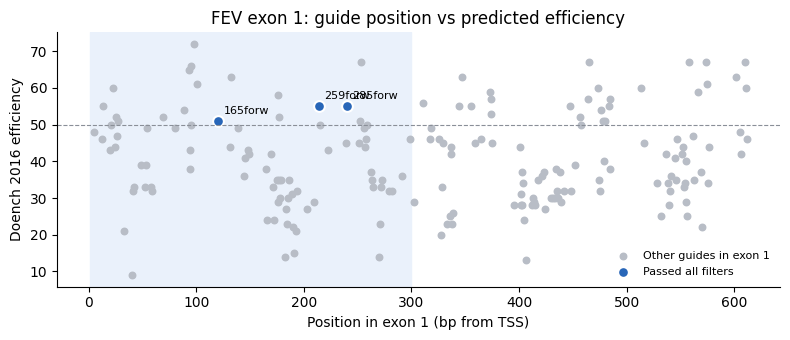

,guideId,protospacer,pam,target_start,target_end,dist_from_TSS,gc_pct,doench16,rule_set3,moreno_mateos,graf,mit_spec,cfd_spec,ot_le2mm,ot_mm3
14,285forw,GTTGGAGACTTTATTGCGAT,GGG,218985396,218985418,240,40.0,55,-63,66,GrafOK,93,93,0,3
71,259forw,GGGTGCGCTTGGCTGTGGCG,CGG,218985422,218985444,214,75.0,55,61,57,GrafOK,72,80,0,17
10,165forw,GCGGAAAAGACACGCGCTCT,AGG,218985516,218985538,120,60.0,51,-24,54,tt,94,97,0,2


In [10]:
selected = d.sort_values(["doench16", "mit_spec"], ascending=False)    # best efficiency first
selected.to_csv(f"{OUT}/{GENE}_selected_guides.csv", index=False)      # save the survivors

# plot: where each guide sits along exon 1 and how efficient it is predicted to be
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.axvspan(1, 300, color="#EAF1FB")                                    # shaded = CRISPRi window (TSS +1 to +300)
inside = guides[guides.fully_in_exon1]                                 # all guides inside the exon
ax.scatter(inside.dist_from_TSS, inside.doench16, s=22, color="#B8BDC6", label="Other guides in exon 1")
ax.scatter(selected.dist_from_TSS, selected.doench16, s=60, color="#2866B8",
           edgecolor="white", linewidth=1.5, label="Passed all filters")   # selected guides stand out
for r in selected.itertuples():
    ax.annotate(r.guideId, (r.dist_from_TSS, r.doench16), xytext=(4, 5),
                textcoords="offset points", fontsize=8)                # label the selected guides
ax.axhline(50, color="#8A8F98", lw=0.8, ls="--")                       # efficiency cut-off line
ax.set_xlabel("Position in exon 1 (bp from TSS)")
ax.set_ylabel("Doench 2016 efficiency")
ax.set_title("FEV exon 1: guide position vs predicted efficiency")
ax.legend(frameon=False, fontsize=8)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)                                    # cleaner look
plt.tight_layout(); plt.show()

selected[["guideId", "protospacer", "pam", "target_start", "target_end", "dist_from_TSS",
          "gc_pct", "doench16", "rule_set3", "moreno_mateos", "graf", "mit_spec", "cfd_spec", "ot_le2mm", "ot_mm3"]]

## Off-target summary of the selected guides
For each selected guide we list every off-target site with up to 3 mismatches (saved for Task 3) and
count how many fall in an exon or in another gene's CRISPRi window.

In [11]:
sel_ot = o[o.guideId.isin(selected.guideId) & (o.mismatchCount <= 3)].copy()  # off-targets of selected guides
sel_ot["genes_near_tss"] = [";".join(genes_with_window_here(r.chrom, r.start, r.end))
                            for r in sel_ot.itertuples()]                      # genes affected, if any
sel_ot.to_csv(f"{OUT}/{GENE}_offtargets_selected_guides.csv", index=False)    # save for Task 3

summary = sel_ot.groupby("guideId").agg(                                       # one summary row per guide
    off_targets_le3mm=("mismatchCount", "size"),
    in_exons=("locusDesc", lambda s: s.str.startswith("exon").sum()),
    in_crispri_window=("genes_near_tss", lambda s: (s != "").sum()),
    genes=("genes_near_tss", lambda s: ",".join(sorted({x for v in s for x in v.split(";") if x})))).reset_index()
final = selected.merge(summary, on="guideId", how="left").fillna({"off_targets_le3mm": 0, "in_exons": 0,
                                                                   "in_crispri_window": 0, "genes": ""})
final.to_csv(f"{OUT}/{GENE}_selected_guides_offtarget_summary.csv", index=False)
final[["guideId", "recommended", "protospacer", "pam", "doench16", "rule_set3", "moreno_mateos", "graf", "mit_spec", "cfd_spec",
       "off_targets_le3mm", "in_exons", "in_crispri_window", "genes"]]

,guideId,recommended,protospacer,pam,doench16,rule_set3,moreno_mateos,graf,mit_spec,cfd_spec,off_targets_le3mm,in_exons,in_crispri_window,genes
0,285forw,True,GTTGGAGACTTTATTGCGAT,GGG,55,-63,66,GrafOK,93,93,3,0,0,
1,259forw,False,GGGTGCGCTTGGCTGTGGCG,CGG,55,61,57,GrafOK,72,80,17,1,1,PLCXD1
2,165forw,True,GCGGAAAAGACACGCGCTCT,AGG,51,-24,54,tt,94,97,2,1,0,
